# Metrical BDI Analysis

This notebook performs authorship verification on metrical patterns using the BDI (Bootstrap Distance Imposters) algorithm from the [`bdi`](https://github.com/bnagy/bdi) package.

**Pipeline:**
1. Load metrical pattern data from CSV
2. Scale features (StandardScaler)
3. Run BDI verification with `minmax` metric (no feature selection)
4. Compare feature selection variants

In [54]:
import sys

sys.path.insert(0, "/Users/ben/code/bdi")

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import logging

from sklearn.preprocessing import StandardScaler, LabelEncoder

from bdi import BDIVerifier

logging.basicConfig(level="INFO")
logger = logging.getLogger("bdi")

import mpl_fontkit as fk

fk.install("Roboto Condensed")

Font name: `Roboto Condensed`


## Loading the data

In [56]:
raw_df = pd.read_csv("output.csv", encoding="utf-8")
print(f"Loaded {raw_df.shape[0]} rows, {raw_df.shape[1]} columns")
print(f"Authors: {raw_df['Author'].nunique()} unique")
raw_df.head()

Loaded 436 rows, 46 columns
Authors: 28 unique


,Author,Work,Poem,H1SP,H2SP,H3SP,H4SP,H1CF,H2CF,H3CF,...,P4SC,P1WC,P2WC,P3WC,P4WC,ELC,RS,LEO,LEN,PFSD
0,AE,bhc,bhc - 1,0.47,0.61,0.64,0.67,0.15,0.70,0.94,...,0.04,0.15,0.13,0.27,0.95,0.000,4.259122,0.954742,200,0.171447
1,AE,bhc,bhc - 2,0.53,0.63,0.70,0.78,0.22,0.76,0.93,...,0.01,0.14,0.20,0.29,0.98,0.000,4.291656,0.704966,200,0.100000
2,AE,bhc,bhc - 3,0.55,0.56,0.60,0.73,0.19,0.77,0.90,...,0.01,0.13,0.11,0.18,0.95,0.000,4.036385,0.795974,200,0.488659
3,ASt,troilus,troilus - 1,0.44,0.56,0.65,0.61,0.36,0.81,0.87,...,0.01,0.09,0.12,0.26,0.98,0.015,4.629291,1.256739,200,0.222702
4,ASt,troilus,troilus - 2,0.36,0.48,0.56,0.52,0.23,0.64,0.86,...,0.02,0.15,0.07,0.18,0.98,0.005,4.753640,1.014985,200,0.000000


## Factorizing

The BDI code needs numeric labels. We use `LabelEncoder` to convert author names to integers.

In [58]:
print(raw_df["Author"].unique())

<ArrowStringArray>
[ 'AE', 'ASt',  'BB', 'BBi',  'BI',  'BM',  'BS',  'EM',  'HA',  'HM',  'HW',
   'H',  'IS',   'M', 'NLC', 'PDE',  'PR',  'QS', 'RDV',  'RL',  'RT', 'SAC',
  'SR',  'U1',  'U2',  'U3',  'U4',   'X']
Length: 28, dtype: str


In [59]:
label_encoder = LabelEncoder()
labels = label_encoder.fit_transform(raw_df["Author"])
raw_df.insert(1, "author_label", labels)

In [60]:
# Show label mapping
mapping = (
    raw_df[["Author", "author_label"]].drop_duplicates().sort_values("author_label")
)
print(mapping.to_string(index=False))
print(f"\nUnknown (X) label: {raw_df[raw_df['Author'] == 'X']['author_label'].iloc[0]}")

Author  author_label
    AE             0
   ASt             1
    BB             2
   BBi             3
    BI             4
    BM             5
    BS             6
    EM             7
     H             8
    HA             9
    HM            10
    HW            11
    IS            12
     M            13
   NLC            14
   PDE            15
    PR            16
    QS            17
   RDV            18
    RL            19
    RT            20
   SAC            21
    SR            22
    U1            23
    U2            24
    U3            25
    U4            26
     X            27

Unknown (X) label: 27


## Scaling

Fit the scaler on all data, then transform. We use `StandardScaler(with_mean=False)` because the `minmax` metric needs non-negative scores.

In [62]:
numeric_cols = raw_df.select_dtypes(include=["number"]).columns
numeric_cols = numeric_cols[numeric_cols != "author_label"]

scaler = StandardScaler(with_mean=False).fit(raw_df[numeric_cols])
df_scaled = pd.DataFrame(scaler.transform(raw_df[numeric_cols]), columns=numeric_cols)
df_scaled["author_label"] = raw_df["author_label"].values

print(f"Scaled shape: {df_scaled.shape}")
df_scaled.head()

Scaled shape: (436, 44)


,H1SP,H2SP,H3SP,H4SP,H1CF,H2CF,H3CF,H4CF,H1DI,H2DI,...,P1WC,P2WC,P3WC,P4WC,ELC,RS,LEO,LEN,PFSD,author_label
0,4.518320,6.168306,8.700397,8.137175,2.320127,9.549528,16.854375,8.166675,7.562451,1.252216,...,3.431202,2.494200,4.002968,4.181740,0.000000,6.000204,1.002779,200.0,0.505242,0
1,5.095127,6.370546,9.516060,9.473129,3.402852,10.368059,16.675073,7.894452,4.908959,2.253989,...,3.202455,3.837230,4.299484,4.313795,0.000000,6.046038,0.740436,200.0,0.294694,0
2,5.287396,5.662708,8.156623,8.865877,2.938827,10.504481,16.137167,7.213896,4.245587,0.500887,...,2.973709,2.110477,2.668645,4.181740,0.000000,5.686415,0.836023,200.0,1.440047,0
3,4.229916,5.662708,8.836341,7.408473,5.568304,11.050169,15.599262,6.261117,5.174309,3.255762,...,2.058721,2.302338,3.854709,4.313795,0.377013,6.521694,1.319970,200.0,0.656287,1
4,3.460841,4.853749,7.612848,6.315419,3.557527,8.730997,15.419960,5.308339,6.368380,1.502660,...,3.431202,1.343031,2.668645,4.313795,0.125671,6.696875,1.066053,200.0,0.000000,1


## Verification (no feature selection)

We hold out *De operibus* as the problem set and verify against all other authors using the `minmax` metric.

In [64]:
target_text = "operibus"

target_label = raw_df.loc[
    raw_df["Work"] == target_text,
    "author_label"
].iloc[0]

# Split into problem and comparison
problem_mask = raw_df["author_label"] == target_label

problem_X = df_scaled.loc[problem_mask].copy()
comparison_X = df_scaled.loc[~problem_mask].copy()

problem_y = problem_X["author_label"]
comparison_y = comparison_X["author_label"]

# Drop label column for verification
problem_X = problem_X.drop(columns=["author_label"])
comparison_X = comparison_X.drop(columns=["author_label"])

print(f"Problem: {problem_X.shape} | Comparison: {comparison_X.shape}")
print(f"Comparison authors: {sorted(raw_df.loc[~problem_mask, 'Author'].unique())}")

Problem: (1, 43) | Comparison: (435, 43)
Comparison authors: ['AE', 'ASt', 'BB', 'BBi', 'BI', 'BM', 'BS', 'EM', 'H', 'HA', 'HM', 'HW', 'IS', 'M', 'NLC', 'PDE', 'PR', 'QS', 'RDV', 'RL', 'RT', 'SAC', 'SR', 'U1', 'U2', 'U3', 'U4']


In [65]:
rng = np.random.default_rng(42)

# Fit BDI verifier with minmax metric, no feature selection
bdi_mm = BDIVerifier(
    metric="minmax",
    nb_bootstrap_iter=1000,
    rnd_prop=0.5,
    random_state=rng,
)
bdi_mm.fit(comparison_X, comparison_y)

# Verify problem chunks against every candidate author
results = {}
for int_label in sorted(set(comparison_y)):
    str_label = label_encoder.classes_[int_label]
    print(f"...... Testing against: {str_label}")
    try:
        probas = bdi_mm.predict_proba(problem_X, [int_label] * problem_X.shape[0])
        results[str_label] = {"mean": np.mean(probas), "std": np.std(probas)}
        print(f"    Match strength: {np.mean(probas):.4f} ± {np.std(probas):.4f}")
    except Exception as e:
        print(f"    Error: {e}")

09/04/2026 02:06:58 [bdi:INFO] Fitting on 435 documents...
09/04/2026 02:06:58 [bdi:INFO] Predicting on 1 documents


...... Testing against: AE


09/04/2026 02:06:58 [bdi:INFO] Predicting on 1 documents


    Match strength: 0.0000 ± 0.0000
...... Testing against: ASt


09/04/2026 02:06:58 [bdi:INFO] Predicting on 1 documents


...

    Match strength: 0.0340 ± 0.0000
...... Testing against: RDV
    Match strength: 0.0000 ± 0.0000
...... Testing against: RL
    Match strength: 0.5800 ± 0.0000
...... Testing against: RT


09/04/2026 02:06:58 [bdi:INFO] Predicting on 1 documents
09/04/2026 02:06:58 [bdi:INFO] Predicting on 1 documents


    Match strength: 0.8980 ± 0.0000
...... Testing against: SAC
    Match strength: 0.0210 ± 0.0000
...... Testing against: SR
    Match strength: 0.0030 ± 0.0000

09/04/2026 02:06:59 [bdi:INFO] Predicting on 1 documents
09/04/2026 02:06:59 [bdi:INFO] Predicting on 1 documents
09/04/2026 02:06:59 [bdi:INFO] Predicting on 1 documents
09/04/2026 02:06:59 [bdi:INFO] Predicting on 1 documents



...... Testing against: U1
    Match strength: 0.0200 ± 0.0000
...... Testing against: U2
    Match strength: 0.0100 ± 0.0000
...... Testing against: U3
    Match strength: 0.0080 ± 0.0000
...... Testing against: U4
    Match strength: 0.3940 ± 0.0000


In [66]:
# Ordina i risultati per Match Strength (mean), dal più alto al più basso
sorted_results = sorted(
    results.items(),
    key=lambda x: x[1]["mean"],
    reverse=True
)

# Stampa la classifica
print("\n=== Author ranking ===")
for rank, (author, stats) in enumerate(sorted_results, start=1):
    print(
        f"{rank:>2}. {author:<30} "
        f"Match strength: {stats['mean']:.4f} ± {stats['std']:.4f}"
    )


=== Author ranking ===
 1. RT                             Match strength: 0.8980 ± 0.0000
 2. BB                             Match strength: 0.8610 ± 0.0000
 3. RL                             Match strength: 0.5800 ± 0.0000
 4. HW                             Match strength: 0.4980 ± 0.0000
 5. PR                             Match strength: 0.3980 ± 0.0000
 6. U4                             Match strength: 0.3940 ± 0.0000
 7. BI                             Match strength: 0.2680 ± 0.0000
 8. IS                             Match strength: 0.0370 ± 0.0000
 9. QS                             Match strength: 0.0340 ± 0.0000
10. ASt                            Match strength: 0.0330 ± 0.0000
11. SAC                            Match strength: 0.0210 ± 0.0000
12. U1                             Match strength: 0.0200 ± 0.0000
13. BBi                            Match strength: 0.0170 ± 0.0000
14. EM                             Match strength: 0.0130 ± 0.0000
15. U2                             Mat

/var/folders/ly/30xhvdxn4x3bm9847m7w6v080000gn/T/ipykernel_8325/2105876286.py:22: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


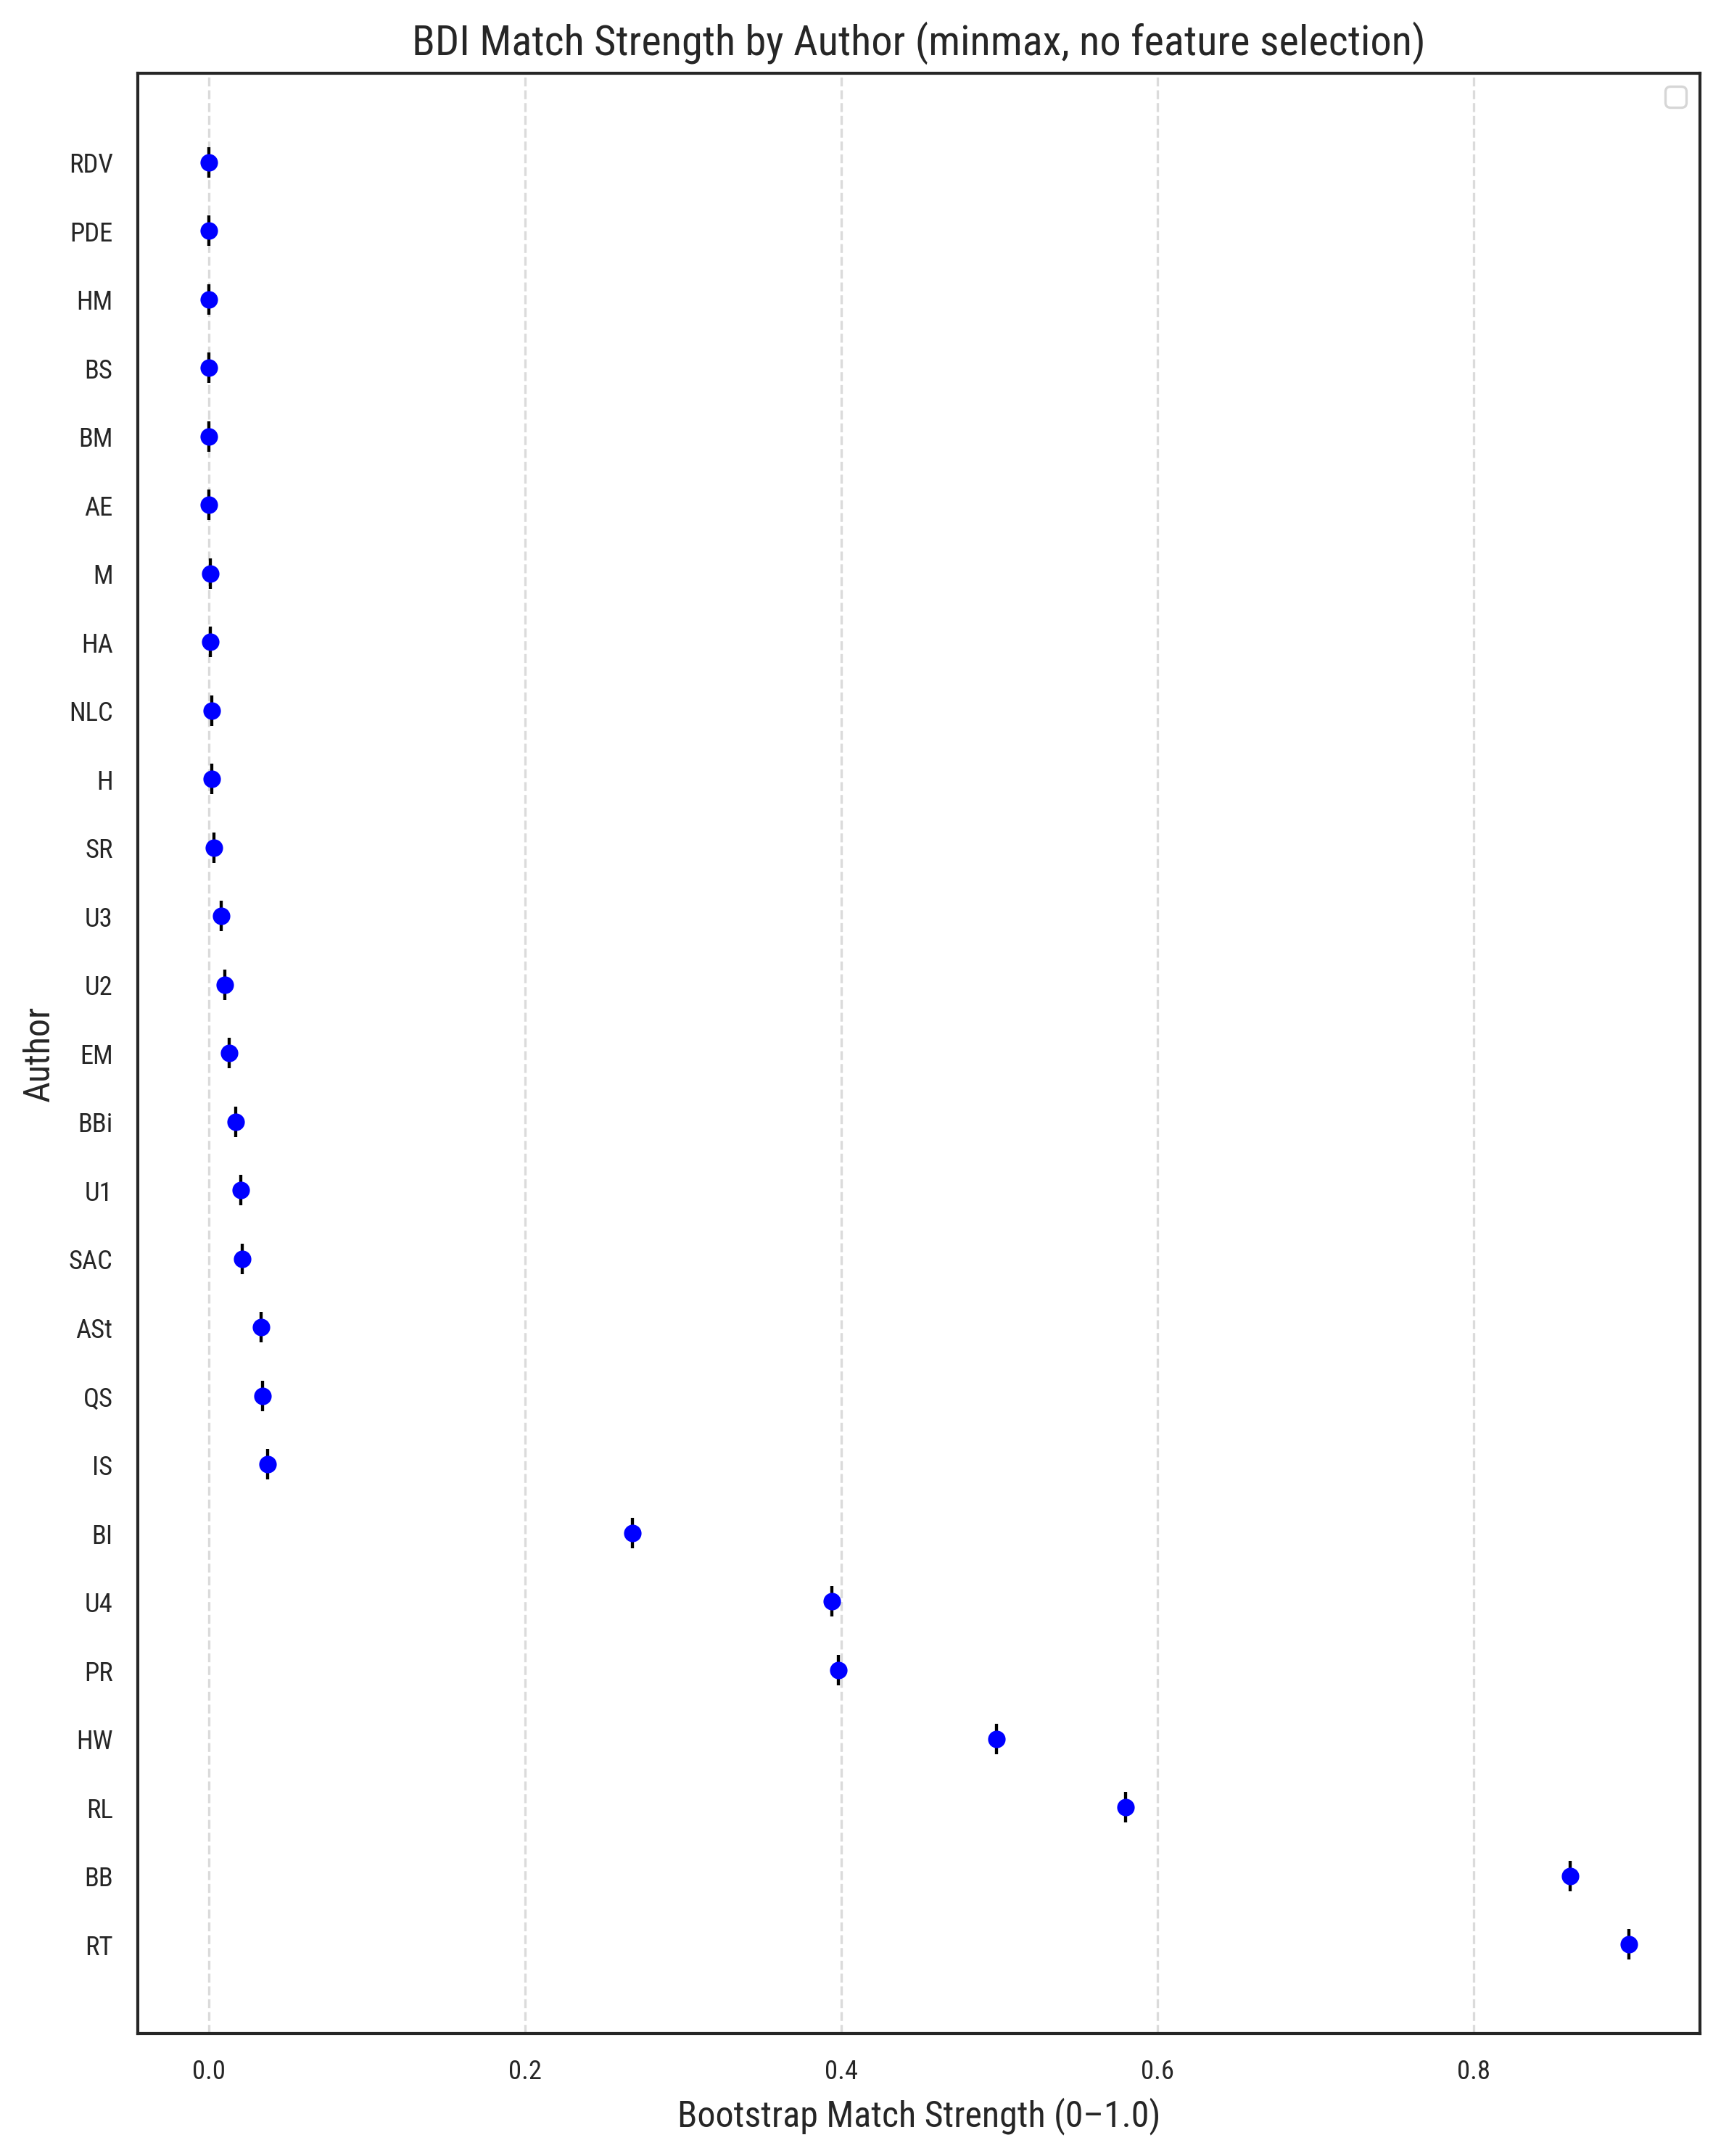

In [67]:
sorted_authors = sorted(results.items(), key=lambda x: x[1]["mean"], reverse=True)

labels_plot = [a[0] for a in sorted_authors]
means = [a[1]["mean"] for a in sorted_authors]
stds = [a[1]["std"] for a in sorted_authors]

fig, ax = plt.subplots(figsize=(8, 10))
ax.errorbar(
    means,
    labels_plot,
    xerr=stds,
    fmt="o",
    color="blue",
    ecolor="black",
    elinewidth=1.5,
    capsize=5,
)
ax.set_xlabel("Bootstrap Match Strength (0–1.0)", fontsize=12)
ax.set_ylabel("Author", fontsize=12)
ax.set_title("BDI Match Strength by Author (minmax, no feature selection)", fontsize=14)
ax.grid(axis="x", linestyle="--", alpha=0.7)
ax.legend()
fig.tight_layout()
plt.savefig("forest_plot_minmax.png", dpi=300, bbox_inches="tight")
plt.show()

## Interpretation

The 'match strength' is the bootstrap percentile of a metric distance of 0. Values over ~0.89 indicate high-precision matches (few false positives). Values below this threshold are *not* reliable negative indicators.

## Chunked Visualization

We can inspect the full bootstrap distance distribution per chunk using `_dist_arrays`. This shows the uncertainty in our determinations.

### Candidate: Hildebert (H)

In [70]:
label_index_H = label_encoder.transform(["H"])[0]

bdi_mm.predict_proba(problem_X, [label_index_H] * problem_X.shape[0])

operibus_vs_hildebert = pd.DataFrame(
    dict(zip(raw_df.loc[problem_mask].index, bdi_mm._dist_arrays))
)
operibus_vs_hildebert

09/04/2026 02:06:59 [bdi:INFO] Predicting on 1 documents


,435
0,-0.103227
1,-0.025497
2,-0.092234
3,-0.034111
4,-0.056720
...,...
995,-0.116217
996,-0.062702
997,-0.020980
998,-0.062064


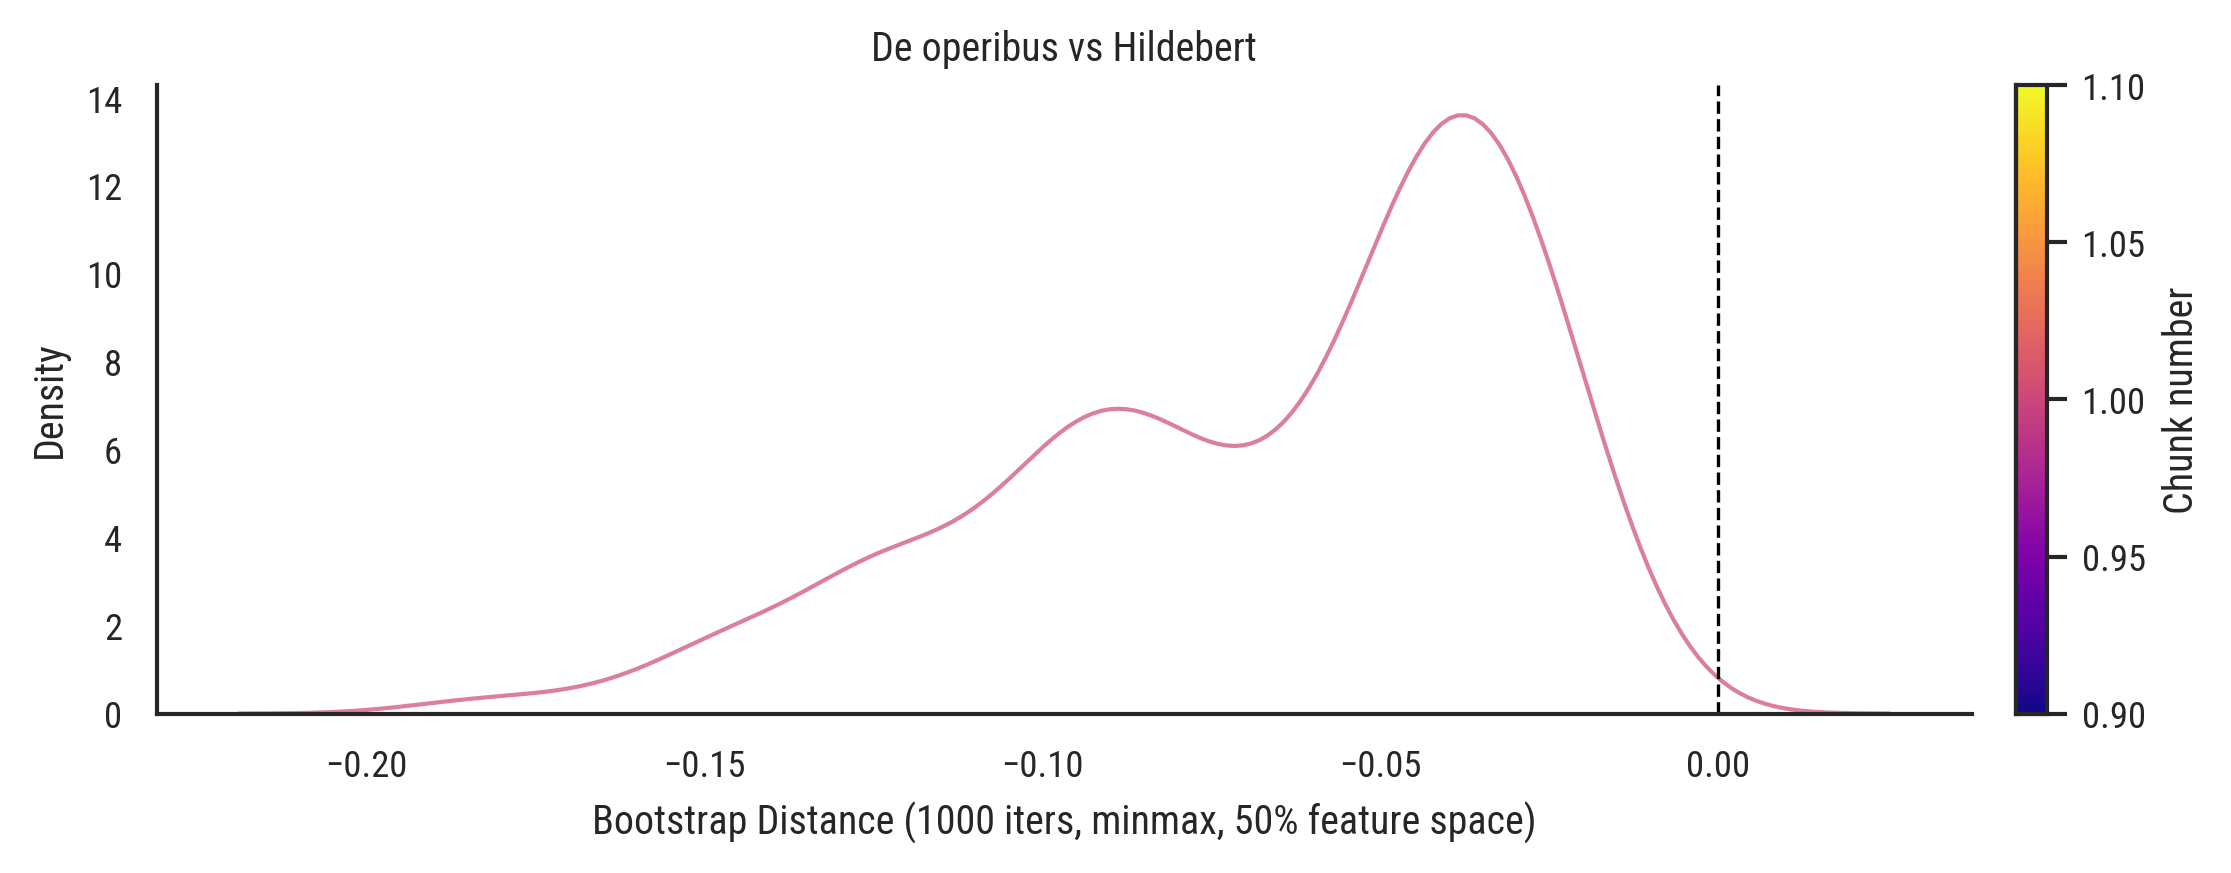

In [71]:
import matplotlib.cm as cm
import matplotlib.colors as mcolors
import re


def plot_kde_viridis(dist_df, poem_names, title="", xlabel="", ax=None):
    """Plot KDE curves colored by chunk number using viridis plasma.

    Later chunks (higher number in poem name) get darker colors.
    """
    # Extract chunk numbers from poem 
    chunk_nums = []
    for idx in dist_df.columns:
        name = poem_names.loc[idx, "Poem"] if idx in poem_names.index else str(idx)
        m = re.search(r"(\d+)", name)
        chunk_nums.append(int(m.group(1)) if m else 0)

    chunk_nums = np.array(chunk_nums)
    n_chunks = len(chunk_nums)

    # Normalize chunk numbers to [0, 1] for colormap
    if chunk_nums.max() > chunk_nums.min():
        norm_vals = (chunk_nums - chunk_nums.min()) / (
            chunk_nums.max() - chunk_nums.min()
        )
    else:
        norm_vals = np.ones(n_chunks) * 0.5

    # Plasma: low values = bright/yellow, high values = dark/purple
    cmap = cm.plasma
    colors = [cmap(v) for v in norm_vals]

    if ax is None:
        fig, ax = plt.subplots(figsize=(8, 3))

    for col, color in zip(dist_df.columns, colors):
        sns.kdeplot(dist_df[col], color=color, linewidth=1, alpha=0.7, ax=ax)

    ax.axvline(0, color="black", linestyle="--", linewidth=0.8)
    ax.set(xlabel=xlabel, ylabel="Density", title=title)

    # Add colorbar as legend
    sm = cm.ScalarMappable(
        cmap=cmap, norm=mcolors.Normalize(vmin=chunk_nums.min(), vmax=chunk_nums.max())
    )
    sm.set_array([])
    cbar = plt.colorbar(sm, ax=ax, pad=0.02)
    cbar.set_label("Chunk number")

    return ax


poem_names = raw_df.loc[problem_mask]

sns.set_theme(
    context="paper",
    font="Roboto Condensed",
    style="white",
    rc={"figure.figsize": (8, 3), "figure.dpi": 300},
)
fig, ax = plt.subplots(figsize=(8, 3))
plot_kde_viridis(
    operibus_vs_hildebert,
    poem_names,
    title="De operibus vs Hildebert",
    xlabel="Bootstrap Distance (1000 iters, minmax, 50% feature space)",
    ax=ax,
)
sns.despine()
fig.tight_layout()
plt.show()

NOTE: BDI match strengths favour precision (few false positives) and should not be interpreted as probabilities.

## Additional Candidates

We test several alternative candidates to compare their bootstrap distance distributions.

09/04/2026 02:07:00 [bdi:INFO] Predicting on 1 documents


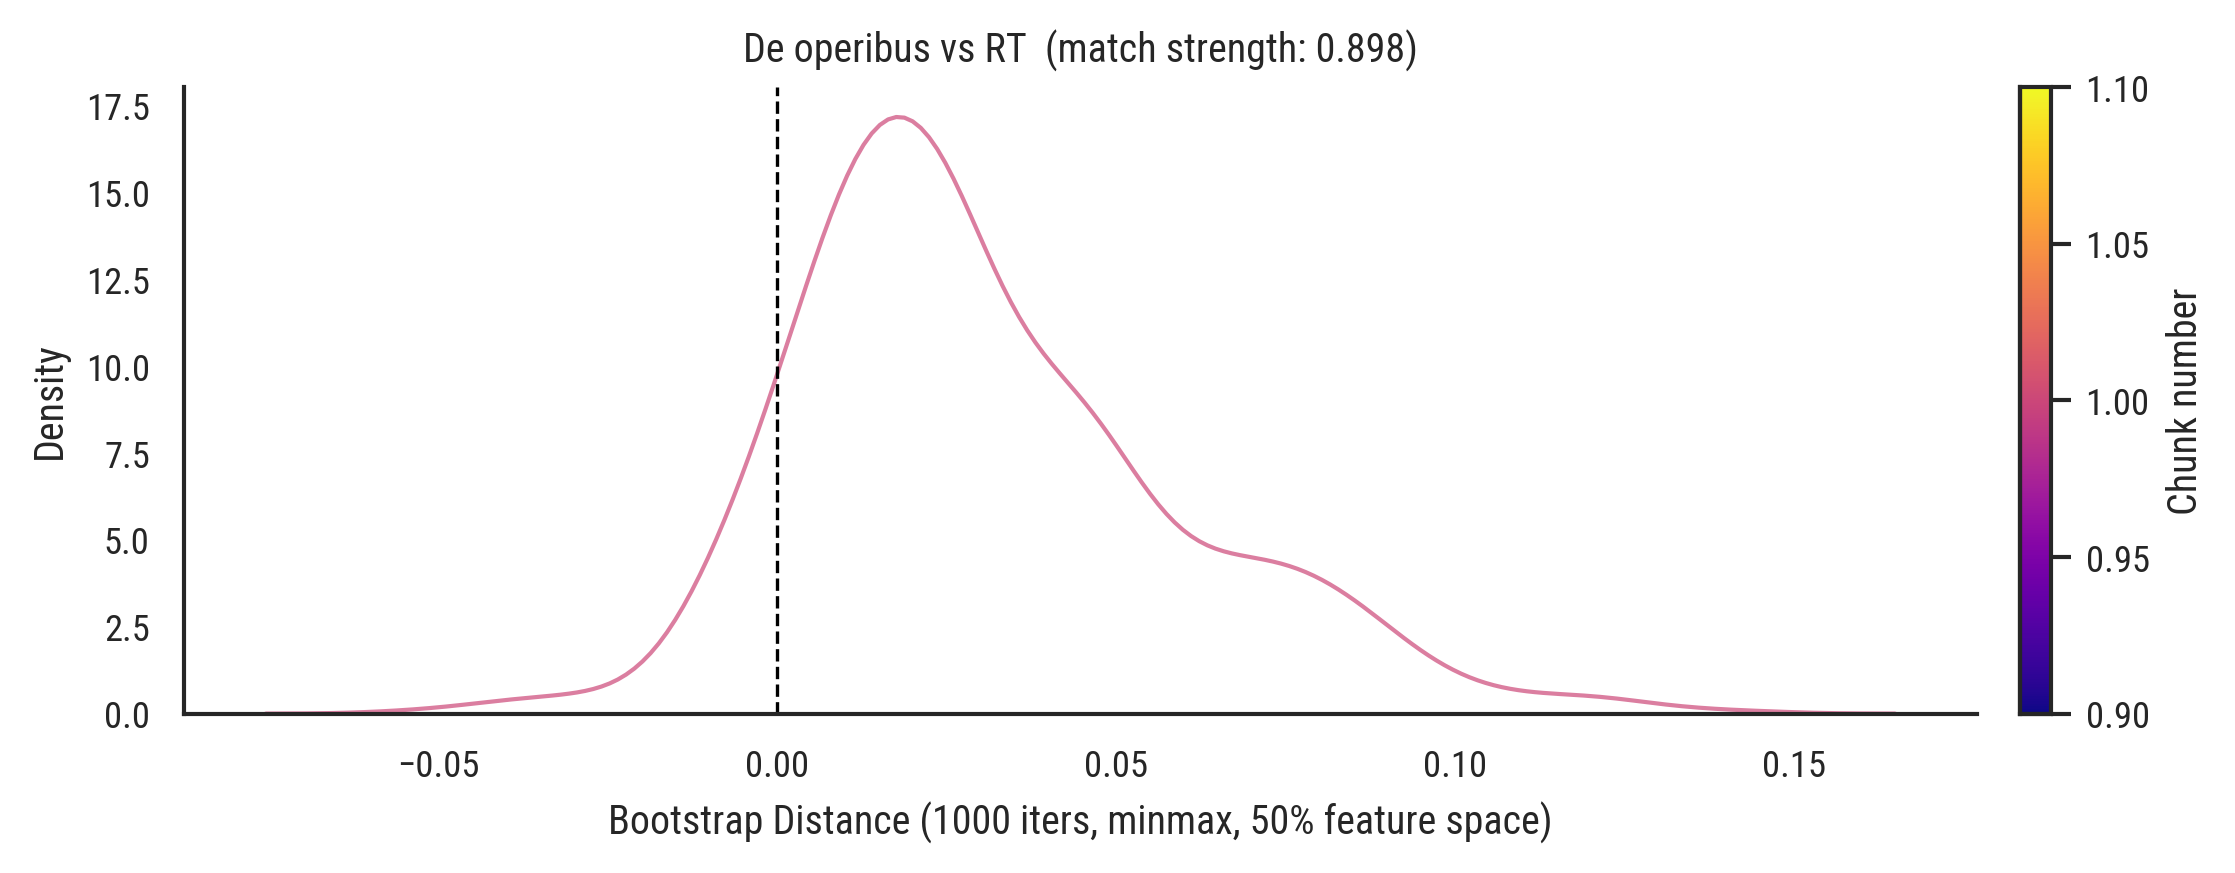

09/04/2026 02:07:00 [bdi:INFO] Predicting on 1 documents


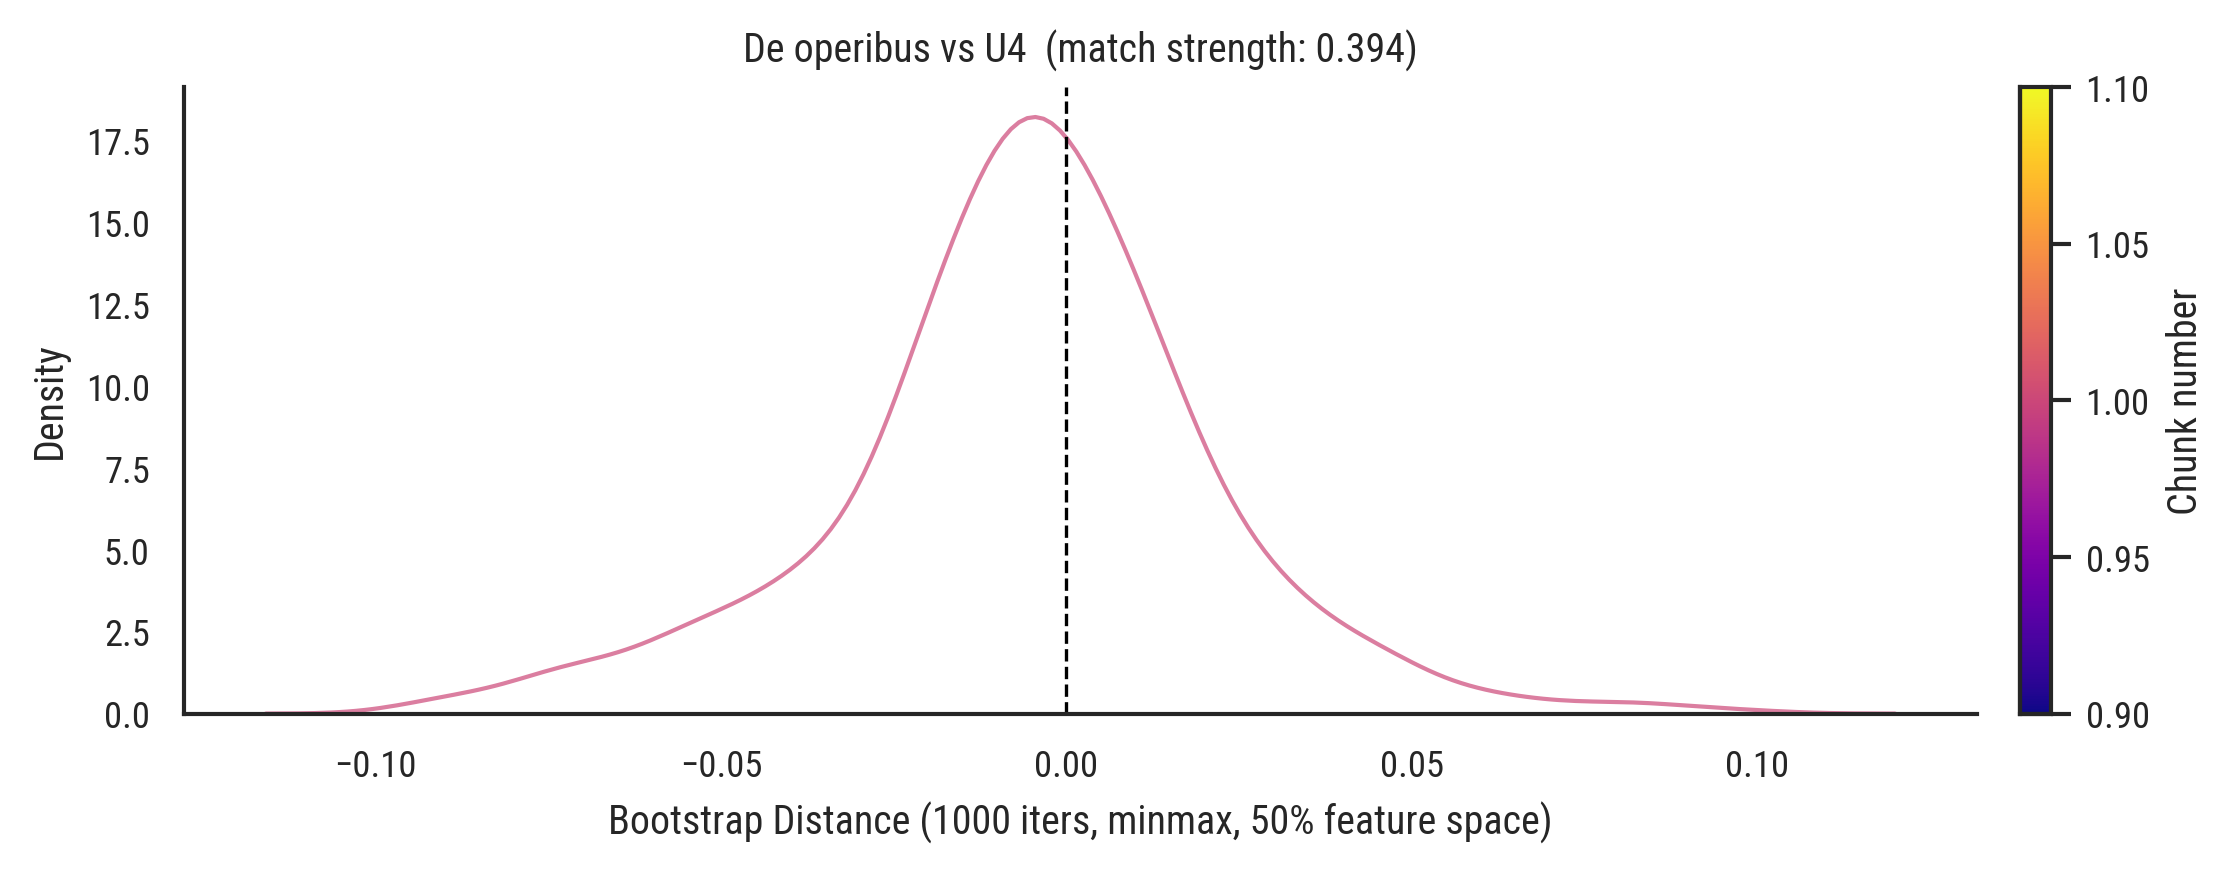

In [73]:
candidates = ["RT", "U4"]

sns.set_theme(
    context="paper",
    font="Roboto Condensed",
    style="white",
    rc={"figure.figsize": (8, 3), "figure.dpi": 300},
)

for candidate in candidates:
    label_idx = label_encoder.transform([candidate])[0]
    bdi_mm.predict_proba(problem_X, [label_idx] * problem_X.shape[0])

    dist_df = pd.DataFrame(
        dict(zip(raw_df.loc[problem_mask].index, bdi_mm._dist_arrays))
    )

    mean_str = results[candidate]["mean"]
    fig, ax = plt.subplots(figsize=(8, 3))
    plot_kde_viridis(
        dist_df,
        poem_names,
        title=f"De operibus vs {candidate}  (match strength: {mean_str:.3f})",
        xlabel="Bootstrap Distance (1000 iters, minmax, 50% feature space)",
        ax=ax,
    )
    sns.despine()
    fig.tight_layout()
    plt.show()

## Feature Selection Variants

The previous analysis used all features. Here we test whether feature selection improves discrimination by comparing three strategies:
- **none**: use all features (baseline)
- **variance_threshold**: remove features with variance below a cutoff (standard approach — low-variance features are less discriminative)
- **fisher_ratio**: keep features with the highest ratio of between-class to within-class variance (ANOVA-style, directly targets discriminative power)

In [75]:
def select_features(
    X: pd.DataFrame,
    y: pd.Series | None = None,
    method: str = "none",
    **kwargs,
) -> pd.Index:
    """Select features (columns) from X based on the given method.

    Args:
        X: Feature DataFrame (samples × features).
        y: Class labels, required for 'fisher_ratio'.
        method: One of 'none', 'variance_threshold', 'fisher_ratio'.
        **kwargs:
            min_variance (float): For 'variance_threshold'.
                Remove features with variance below this value. Default 0.01.
            n_features (int): For 'fisher_ratio'. Keep top N by F-ratio. Default 20.

    Returns:
        pd.Index of selected column names.
    """
    if method == "none":
        return X.columns

    if method == "variance_threshold":
        min_var = kwargs.get("min_variance", 0.01)
        variances = X.var(axis=0)
        keep = variances >= min_var
        return X.columns[keep]

    if method == "fisher_ratio":
        if y is None:
            raise ValueError("fisher_ratio requires class labels (y).")
        n = kwargs.get("n_features", 20)
        classes = y.unique()
        overall_mean = X.mean(axis=0)
        between_var = pd.Series(0.0, index=X.columns)
        within_var = pd.Series(0.0, index=X.columns)
        for c in classes:
            mask = y == c
            n_c = mask.sum()
            class_mean = X.loc[mask].mean(axis=0)
            class_var = X.loc[mask].var(axis=0)
            between_var += n_c * (class_mean - overall_mean) ** 2
            within_var += (n_c - 1) * class_var
        # Avoid division by zero
        within_var = within_var.replace(0, np.nan)
        f_ratio = between_var / within_var
        f_ratio = f_ratio.fillna(0).sort_values(ascending=False)
        return f_ratio.head(n).index

    raise ValueError(
        f"Unknown method: {method}. Choose from 'none', 'variance_threshold', 'fisher_ratio'."
    )


# Quick sanity check
assert len(select_features(comparison_X, method="none")) == comparison_X.shape[1]
vt_cols = select_features(comparison_X, method="variance_threshold")
assert len(vt_cols) <= comparison_X.shape[1]
print(f"variance_threshold: {len(vt_cols)} / {comparison_X.shape[1]} features")
fr_cols = select_features(
    comparison_X, y=comparison_y, method="fisher_ratio", n_features=10
)
assert len(fr_cols) == 10
print("select_features() sanity checks passed.")

variance_threshold: 42 / 43 features
select_features() sanity checks passed.


In [76]:
# Run BDI for each feature selection method
variant_results = {}
rng2 = np.random.default_rng(42)

for method_name in ["none", "variance_threshold", "fisher_ratio"]:
    print(f"\n{'='*60}")
    print(f"Feature selection: {method_name}")
    print(f"{'='*60}")

    # Select features
    if method_name == "fisher_ratio":
        selected = select_features(
            comparison_X, y=comparison_y, method=method_name, n_features=38
        )
    elif method_name == "variance_threshold":
        selected = select_features(comparison_X, method=method_name, min_variance=0.05)
    else:
        selected = select_features(comparison_X, method=method_name)

    comp_X = comparison_X[selected].copy()
    prob_X = problem_X[selected].copy()
    print(f"  Features used: {len(selected)}")
    print(f"  Features Dropped: {set(comparison_X.columns) - set(selected)}")

    # Fit and predict
    verifier = BDIVerifier(
        metric="minmax",
        nb_bootstrap_iter=2000,
        rnd_prop=0.35,
        random_state=rng2,
    )
    verifier.fit(comp_X, comparison_y)

    method_results = {}
    for int_label in sorted(set(comparison_y)):
        str_label = label_encoder.classes_[int_label]
        try:
            probas = verifier.predict_proba(prob_X, [int_label] * prob_X.shape[0])
            method_results[str_label] = {"mean": np.mean(probas), "std": np.std(probas)}
        except Exception as e:
            print(f"  Error for {str_label}: {e}")

    variant_results[method_name] = method_results
    # Show top 5
    top5 = sorted(method_results.items(), key=lambda x: x[1]["mean"], reverse=True)[:5]
    for author, vals in top5:
        print(f"  {author}: {vals['mean']:.4f} ± {vals['std']:.4f}")

09/04/2026 02:07:00 [bdi:INFO] Fitting on 435 documents...
09/04/2026 02:07:00 [bdi:INFO] Predicting on 1 documents
09/04/2026 02:07:00 [bdi:INFO] Predicting on 1 documents
09/04/2026 02:07:00 [bdi:INFO] Predicting on 1 documents



Feature selection: none
  Features used: 43
  Features Dropped: set()


09/04/2026 02:07:00 [bdi:INFO] Predicting on 1 documents
09/04/2026 02:07:00 [bdi:INFO] Predicting on 1 documents
09/04/2026 02:07:00 [bdi:INFO] Predicting on 1 documents
09/04/2026 02:07:00 [bdi:INFO] Predicting on 1 documents
09/04/2026 02:07:01 [bdi:INFO] Predicting on 1 documents
09/04/2026 02:07:01 [bdi:INFO] Predicting on 1 documents
09/04/2026 02:07:01 [bdi:INFO] Predicting on 1 documents
09/04/2026 02:07:01 [bdi:INFO] Predicting on 1 documents
09/04/2026 02:07:01 [bdi:INFO] Predicting on 1 documents
09/04/2026 02:07:01 [bdi:INFO] Predicting on 1 documents
09/04/2026 02:07:01 [bdi:INFO] Predicting on 1 documents
09/04/2026 02:07:01 [bdi:INFO] Predicting on 1 documents
09/04/2026 02:07:01 [bdi:INFO] Predicting on 1 documents
09/04/2026 02:07:01 [bdi:INFO] Predicting on 1 documents
09/04/2026 02:07:01 [bdi:INFO] Predicting on 1 documents
09/04/2026 02:07:01 [bdi:INFO] Predicting on 1 documents
09/04/2026 02:07:01 [bdi:INFO] Predicting on 1 documents
09/04/2026 02:07:02 [bdi:INFO] 

  RT: 0.8415 ± 0.0000
  BB: 0.7505 ± 0.0000
  RL: 0.5260 ± 0.0000
  HW: 0.5200 ± 0.0000
  PR: 0.4170 ± 0.0000

Feature selection: variance_threshold
  Features used: 42
  Features Dropped: {'LEN'}


09/04/2026 02:07:02 [bdi:INFO] Predicting on 1 documents
09/04/2026 02:07:02 [bdi:INFO] Predicting on 1 documents
09/04/2026 02:07:02 [bdi:INFO] Predicting on 1 documents
09/04/2026 02:07:02 [bdi:INFO] Predicting on 1 documents
09/04/2026 02:07:03 [bdi:INFO] Predicting on 1 documents
09/04/2026 02:07:03 [bdi:INFO] Predicting on 1 documents
09/04/2026 02:07:03 [bdi:INFO] Predicting on 1 documents
09/04/2026 02:07:03 [bdi:INFO] Predicting on 1 documents
09/04/2026 02:07:03 [bdi:INFO] Predicting on 1 documents
09/04/2026 02:07:03 [bdi:INFO] Predicting on 1 documents
09/04/2026 02:07:03 [bdi:INFO] Predicting on 1 documents
09/04/2026 02:07:03 [bdi:INFO] Predicting on 1 documents
09/04/2026 02:07:03 [bdi:INFO] Predicting on 1 documents
09/04/2026 02:07:03 [bdi:INFO] Predicting on 1 documents
09/04/2026 02:07:03 [bdi:INFO] Predicting on 1 documents
09/04/2026 02:07:03 [bdi:INFO] Predicting on 1 documents
09/04/2026 02:07:03 [bdi:INFO] Predicting on 1 documents
09/04/2026 02:07:04 [bdi:INFO] 

  RT: 0.8140 ± 0.0000
  BB: 0.7425 ± 0.0000
  RL: 0.5480 ± 0.0000
  HW: 0.5235 ± 0.0000
  PR: 0.4470 ± 0.0000

Feature selection: fisher_ratio
  Features used: 38
  Features Dropped: {'P2CF', 'P2DI', 'P2SC', 'H3DI', 'LEN'}


09/04/2026 02:07:04 [bdi:INFO] Predicting on 1 documents
09/04/2026 02:07:04 [bdi:INFO] Predicting on 1 documents
09/04/2026 02:07:04 [bdi:INFO] Predicting on 1 documents
09/04/2026 02:07:04 [bdi:INFO] Predicting on 1 documents
09/04/2026 02:07:04 [bdi:INFO] Predicting on 1 documents
09/04/2026 02:07:05 [bdi:INFO] Predicting on 1 documents
09/04/2026 02:07:05 [bdi:INFO] Predicting on 1 documents
09/04/2026 02:07:05 [bdi:INFO] Predicting on 1 documents
09/04/2026 02:07:05 [bdi:INFO] Predicting on 1 documents
09/04/2026 02:07:05 [bdi:INFO] Predicting on 1 documents
09/04/2026 02:07:05 [bdi:INFO] Predicting on 1 documents
09/04/2026 02:07:05 [bdi:INFO] Predicting on 1 documents
09/04/2026 02:07:05 [bdi:INFO] Predicting on 1 documents
09/04/2026 02:07:05 [bdi:INFO] Predicting on 1 documents
09/04/2026 02:07:05 [bdi:INFO] Predicting on 1 documents
09/04/2026 02:07:05 [bdi:INFO] Predicting on 1 documents
09/04/2026 02:07:05 [bdi:INFO] Predicting on 1 documents
09/04/2026 02:07:05 [bdi:INFO] 

  BB: 0.7905 ± 0.0000
  RT: 0.7900 ± 0.0000
  HW: 0.5745 ± 0.0000
  RL: 0.5585 ± 0.0000
  U4: 0.4070 ± 0.0000


### Variant Comparison

Compare how the three feature selection strategies affect the top-ranked candidates.

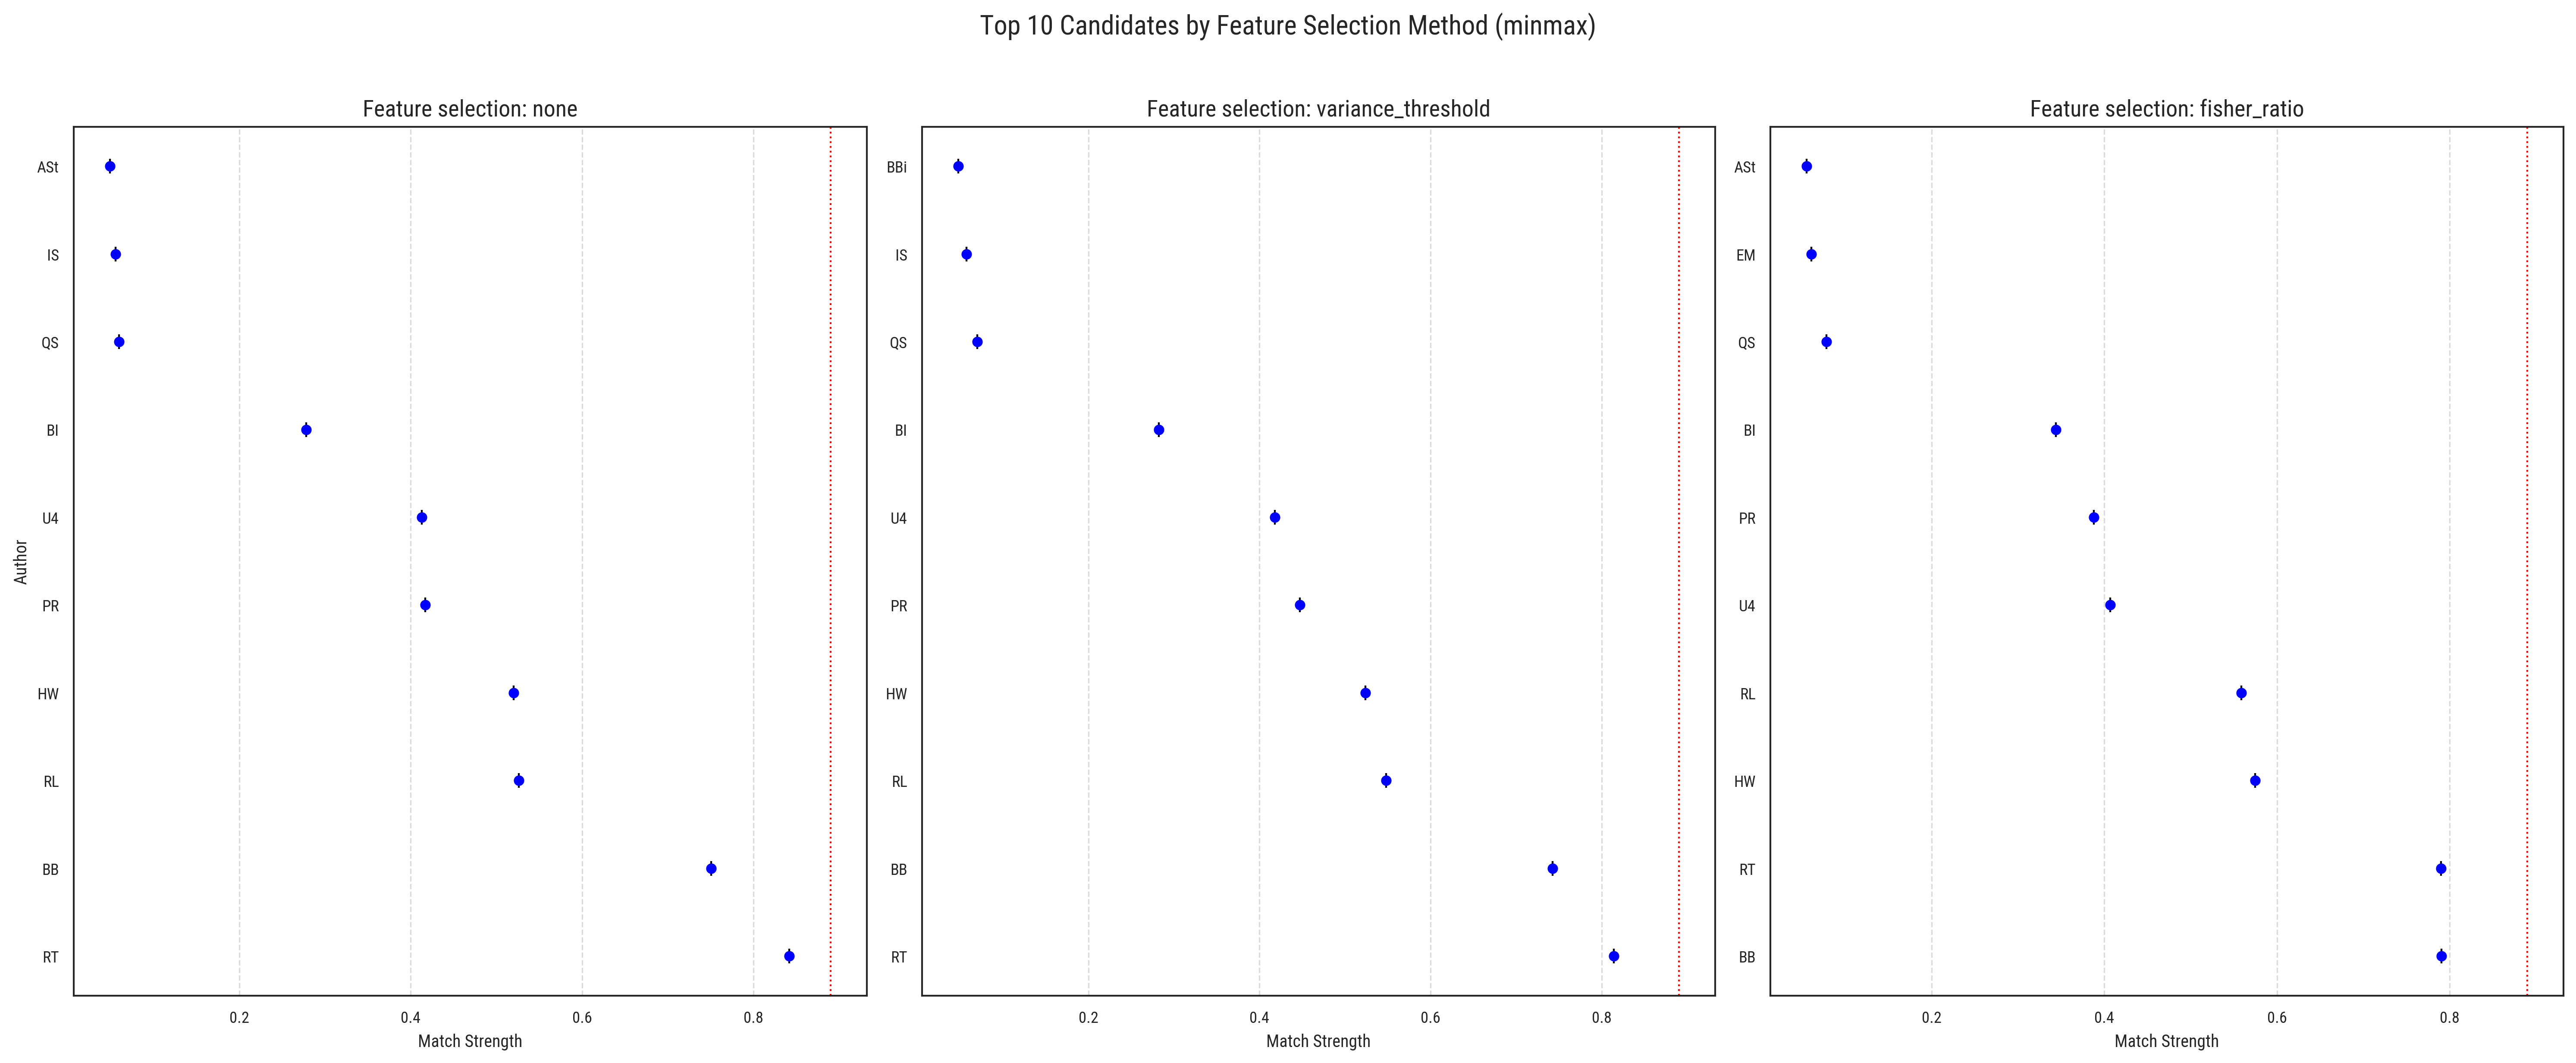

In [78]:
# Show top 10 for each variant side by side
fig, axes = plt.subplots(1, 3, figsize=(20, 8), sharey=False)

for ax, (method_name, res) in zip(axes, variant_results.items()):
    sorted_r = sorted(res.items(), key=lambda x: x[1]["mean"], reverse=True)[:10]
    labels_m = [r[0] for r in sorted_r]
    means_m = [r[1]["mean"] for r in sorted_r]
    stds_m = [r[1]["std"] for r in sorted_r]

    ax.errorbar(
        means_m,
        labels_m,
        xerr=stds_m,
        fmt="o",
        color="blue",
        ecolor="black",
        elinewidth=1.5,
        capsize=4,
    )
    ax.set_title(f"Feature selection: {method_name}", fontsize=13)
    ax.set_xlabel("Match Strength")
    ax.axvline(0.89, color="red", linestyle=":", linewidth=1)
    ax.grid(axis="x", linestyle="--", alpha=0.7)

axes[0].set_ylabel("Author")
fig.suptitle(
    "Top 10 Candidates by Feature Selection Method (minmax)", fontsize=15, y=1.02
)
fig.tight_layout()
plt.savefig("feature_selection_comparison.png", dpi=300, bbox_inches="tight")
plt.show()